# 03 — Evaluation and Results

## Scientific question

**Does the model generate plausible avatars, follow requested attributes, and generalize compositionally?**

All reported metrics come from the validated frozen-results loader. This notebook does not open result JSON files or recompute any metric.

## Environment & reproducibility setup

In [1]:
from __future__ import annotations

import json
import platform
from importlib.metadata import version
from pathlib import Path


def find_project_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / "src" / "tiny_avatar_diffusion").is_dir():
            return candidate
    raise RuntimeError(
        "Repository root not found. Run this notebook from inside the Tiny Avatar Diffusion repository."
    )


PROJECT_ROOT = find_project_root()
environment = {
    "python": platform.python_version(),
    "package": version("tiny-avatar-diffusion"),
    "project_root": PROJECT_ROOT.name,
    "project_markers_verified": True,
}
environment

{'python': '3.12.4',
 'package': '0.0.0',
 'project_root': 'DL_Project',
 'project_markers_verified': True}

In [2]:
import matplotlib.pyplot as plt
from tiny_avatar_diffusion.frozen_results import load_frozen_results

results = load_frozen_results()
sorted(results)

['conditioning',
 'latency',
 'lpips_diversity_global_prompt_macro',
 'memory',
 'parameter_counts',
 'quality_by_split',
 'quality_global']

## Evaluation questions and evaluator protocol

Evaluation separates three questions: attribute adherence, distribution-level image quality, and perceptual diversity/engineering cost.

The attribute evaluator is a separate scratch CNN trained only on real Cartoon100k data. Its protocol separates evaluator training and validation from real-image ceiling panels. The architecture is a 32→64→128 CNN, global average pooling to a 128-dimensional representation, and four attribute-specific heads. It diagnoses generated images; it is not part of the generator.

In [3]:
from tiny_avatar_diffusion.evaluator import ARCHITECTURE_ID, parameter_count

evaluator_identity = {
    "architecture": ARCHITECTURE_ID,
    "parameter_count": parameter_count(),
    "role": "separate real-data-trained diagnostic/evaluation model",
}
evaluator_identity

{'architecture': 'dr04_shared_cnn_32_64_128_gap_linear_heads_v1',
 'parameter_count': 293064,
 'role': 'separate real-data-trained diagnostic/evaluation model'}

## Conditioning adherence and ID vs compositional OOD

In [4]:
conditioning = results["conditioning"]
conditioning_summary = {
    "ID MAA": conditioning["id_maa"],
    "ID marginal bootstrap 95% interval": conditioning["id_maa_bootstrap_95"],
    "OOD MAA": conditioning["ood_maa"],
    "OOD marginal bootstrap 95% interval": conditioning["ood_maa_bootstrap_95"],
    "Absolute ID → OOD gap (point estimate only)": conditioning["absolute_maa_gap"],
    "MacroPSR": conditioning["macro_psr"],
}
conditioning_summary

{'ID MAA': 0.5223684210526316,
 'ID marginal bootstrap 95% interval': {'lower': 0.49835526315789475,
  'upper': 0.5463815789473685},
 'OOD MAA': 0.425,
 'OOD marginal bootstrap 95% interval': {'lower': 0.4010000000000001,
  'upper': 0.44900000000000007},
 'Absolute ID → OOD gap (point estimate only)': 0.0973684210526316,
 'MacroPSR': 0.224}

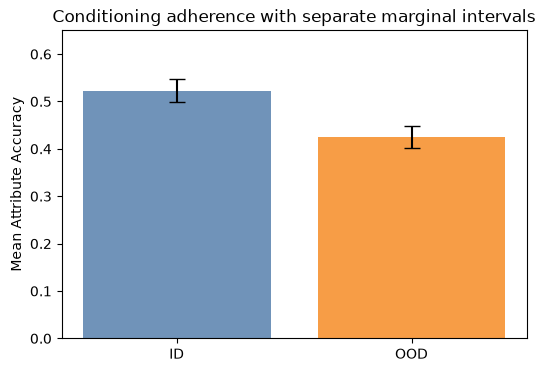

In [5]:
labels = ["ID", "OOD"]
means = [conditioning["id_maa"], conditioning["ood_maa"]]
intervals = [conditioning["id_maa_bootstrap_95"], conditioning["ood_maa_bootstrap_95"]]
lower_errors = [mean - interval["lower"] for mean, interval in zip(means, intervals, strict=True)]
upper_errors = [interval["upper"] - mean for mean, interval in zip(means, intervals, strict=True)]

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(labels, means, color=["#4c78a8", "#f58518"], alpha=0.8)
ax.errorbar(labels, means, yerr=[lower_errors, upper_errors], fmt="none", color="black", capsize=6)
ax.set(ylabel="Mean Attribute Accuracy", title="Conditioning adherence with separate marginal intervals", ylim=(0, 0.65))
plt.show()

The displayed 95% bootstrap intervals quantify uncertainty separately for ID and OOD MAA. **No canonical bootstrap confidence interval is available for the ID→OOD gap.** The gap is reported as a point estimate only. The marginal intervals are not a significance test, p-value, or evidence of causality.

## QUALITY != CONDITIONING

MAA and MacroPSR measure adherence to requested structured attributes. KID and FID measure distribution-level generative quality. They answer different questions and are never merged into one score.

In [6]:
def markdown_table(headers: list[str], rows: list[list[object]]) -> str:
    separator = ["---"] * len(headers)
    lines = ["| " + " | ".join(headers) + " |", "| " + " | ".join(separator) + " |"]
    lines.extend("| " + " | ".join(str(value) for value in row) + " |" for row in rows)
    return "\n".join(lines)

quality_rows = []
for model, splits in results["quality_by_split"].items():
    for split, metrics in splits.items():
        quality_rows.append([model.title(), split.upper(), metrics["kid"], metrics["fid"]])

from IPython.display import Markdown, display
display(Markdown(markdown_table(["Model", "Split", "KID", "FID"], quality_rows)))

| Model | Split | KID | FID |
| --- | --- | --- | --- |
| Conditional | ID | 0.019295956939458847 | 49.37773171781788 |
| Conditional | OOD | 0.019467167556285858 | 58.702624366029426 |
| Unconditional | ID | 0.02868834137916565 | 58.08331071638449 |
| Unconditional | OOD | 0.04378482326865196 | 83.18393889462249 |

Lower KID/FID is better under the frozen evaluation protocol. These metrics do **not** measure whether requested attributes were followed.

## Diversity and engineering

In [7]:
engineering_rows = []
for model in ("conditional", "unconditional"):
    for batch in ("batch_1", "batch_16"):
        engineering_rows.append(
            [
                model.title(),
                batch.removeprefix("batch_"),
                results["parameter_counts"][model],
                results["latency"][model][batch]["median_seconds_per_image"],
                results["memory"][model][batch]["peak_allocated_mib"],
            ]
        )
display(Markdown(markdown_table(
    ["Model", "Batch", "Parameters", "Median seconds/image", "Peak allocated MiB"],
    engineering_rows,
)))
{"prompt_macro_LPIPS": results["lpips_diversity_global_prompt_macro"]}

| Model | Batch | Parameters | Median seconds/image | Peak allocated MiB |
| --- | --- | --- | --- | --- |
| Conditional | 1 | 4723907 | 8.746576350007672 | 29.81884765625 |
| Conditional | 16 | 4723907 | 0.6305745937497704 | 77.73095703125 |
| Unconditional | 1 | 4595779 | 7.567574749991763 | 29.30859375 |
| Unconditional | 16 | 4595779 | 0.5521374531244874 | 77.0185546875 |

{'prompt_macro_LPIPS': 0.03617095261191328}

Higher LPIPS indicates greater perceptual variation under the evaluated protocol; it is not universally “better.” Latency and memory are measurements from the frozen benchmark environment and protocol, not universal hardware benchmarks.

## Integrated interpretation and limitations

The conditional model has better frozen distribution-level KID/FID than the unconditional baseline for both reported splits. Conditioning adherence is moderate and decreases from ID to unseen combinations. Taken together, the evidence supports **partial rather than robust compositional control**.

This is a descriptive conclusion. The available marginal bootstrap intervals do not establish significance for the ID→OOD gap, the evaluator is itself an imperfect diagnostic model, and 32×32 avatar results should not be generalized beyond the frozen protocol.